#### Steps for getting from output to figures:
1. Set:
    - paths: project and results
    - Data files to load
    - Output figure name
    - Subjects to exclude
2. Import packages
3. Load data sets
4. Reformat data frame
    - concatenate different classifiers
    - reset index
    - Variable formatting:
        - subject -> ordered type
        - Classifier -> categorical
    - Drop duplicates
5. Drop t_0 (for window=1000, step=500)* 
6. Melt accuracy of train and test into separate rows titled 'performance'*

*For 1000ms window results:

_____________

#### 1. Set variables & paths </big>
 - Paths: project and results
 - Data files to load
 - Output figure name
 - Subjects to exclude

In [1]:
project_path = '/project_data/volume0/tpirnia/data/EEGWS/'
results_path = 'data/across_subjects/results/ch2_attempt6/us/'
fname_root = 'ch2-_us_c_avg.3reps_w1000_s500-rep3-2'

data_fnames = ['results_'+fname_root+'_ridge.csv',
               'results_'+fname_root+'_log.csv','results_'+fname_root+'_svm.csv']

# data_fnames = ['results_'+fname_root+'_svm.csv']

fig_fname = 'fig_' + fname_root # add ending

exclude_subjects = ['EP24']

#### 2. Import packages

In [2]:
import os, sys
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl


import seaborn as sns

sys.path.append(project_path + '/maybe_repo')
# from utils.utils import save_output

#### 3. Load data sets  </big>
 - load each set
 - concatenate different sets (i.e. results by classifier)
 - reset index

In [3]:
main_df = []
for _fname in data_fnames:
    _df = pd.read_csv(''.join([project_path,
                               results_path,
                               _fname,
                              ])) #,usecols=list(np.arange(8))
    main_df.append(pd.DataFrame(_df))

main_df = pd.concat(main_df,
                ignore_index=True)
main_df.reset_index(inplace=True, 
                    drop=True)

In [4]:
main_df.head(3)

,subject,classifier,window,step,w_train,train_accuracy,t_0,t_500
0,EP03,ridge,1000,500,1,0.666667,0.650000,0.691667
1,EP05,ridge,1000,500,1,0.837500,0.733333,0.866667
2,EP06,ridge,1000,500,1,0.666667,0.541667,0.733333


#### 4. Reformat data frame
 - Remove extra data:
     - only keep columns [0:train_accuracy] + [test_accuracy]
     - remove duplicates
 - Variable formatting:
     - subject -> ordered type
     - Classifier -> categorical

In [5]:
train_ind, test_ind = main_df.columns.get_indexer(['train_accuracy','t_500'])
keep_cols_ind = list(np.arange(train_ind+1)) + [test_ind]
del_cols_ind = np.delete(np.arange(len(main_df.columns)), keep_cols_ind)

print('Columns to keep:',main_df.columns.values[keep_cols_ind],
     '\nColumns to remove:',main_df.columns.values[del_cols_ind])

Columns to keep: ['subject' 'classifier' 'window' 'step' 'w_train' 'train_accuracy' 't_500'] 
Columns to remove: ['t_0']


In [6]:
main_df.drop(main_df.columns[del_cols_ind],axis=1, inplace=True)

In [7]:
main_df = main_df.drop_duplicates()

In [129]:
# if I want to only look at w_train=1
# main_df.loc[main_df['w_train']==1].head(3)#.copy

In [8]:
col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             't_500': 'Test Accuracy',
            }
main_df.rename(columns=col_renames,
               inplace=True)

In [9]:
main_df.head(3)

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,ridge,1000,500,1,0.666667,0.691667
1,EP05,ridge,1000,500,1,0.837500,0.866667
2,EP06,ridge,1000,500,1,0.666667,0.733333


In [10]:
# change subjects to ordered type
# a

clfs = {'ridge':'Ridge','log':'Logistic','svm':'SVM'}
for _c in clfs:
    _inds = (main_df['Classifier'] == _c)
    main_df.loc[_inds,'Classifier'] = clfs[_c]

_cattype = pd.api.types.CategoricalDtype(categories=list(clfs.values()),
                                         ordered=True)
main_df['Classifier'] = main_df['Classifier'].astype(_cattype)

#### 5. Drop t_0 (for window=1000, step=500)* 

In [11]:
if 't_0' in main_df.columns:
    main_df = main_df.drop('t_0', axis=1)

#### 6. Melt accuracy of train and test into separate rows titled 'performance'*

In [12]:
# Dataframe for train/test classification 
_df = main_df.melt(id_vars=['Subject',
                            'Classifier',
                            'Trial Length',
                            'step',
                            'w_train'],
                   var_name='Performance',
                   value_name='Accuracy')

_inds_tr, _inds_te = (_df['Performance'] == 'Train Accuracy'),(_df['Performance'] == 'Test Accuracy')
_df.loc[_inds_tr,'Performance'] = 'Train'
_df.loc[_inds_te,'Performance'] = 'Test'


In [13]:
plt.rcParams.update(plt.rcParamsDefault)
# %matplotlib inline
# plt.style.use('seaborn-darkgrid')
# plt.style.use('seaborn-poster')

In [14]:
#plot parameters:
params = {'lines.markersize':6,
          'axes.labelsize': 20,
          'axes.titlesize':20,
          'axes.labelpad':8,
          'xtick.labelsize' :16,
          'ytick.labelsize' :16,
          'xtick.major.pad':7, 
          'ytick.major.pad':6, 
          'legend.labelspacing':.5,
          'legend.handletextpad':.175,
          'legend.title_fontsize':20,
          'legend.fontsize':20,
          'figure.figsize':(8,10),
          'figure.subplot.hspace': .95,
          'figure.subplot.wspace': .95,
          'image.origin': 'lower',
          'figure.autolayout': False,
          'scatter.marker':'o',
          'savefig.dpi': 450,
          'savefig.bbox': 'tight',
          'savefig.transparent': True,
         }

In [18]:
_df.groupby(by='Classifier').mean()

,Trial Length,step,w_train,Accuracy
Classifier,,,,
Ridge,1000,500,1,0.683333
Logistic,1000,500,1,0.690104
SVM,1000,500,1,0.839286


In [19]:
_df.groupby(by='Classifier').std()

,Trial Length,step,w_train,Accuracy
Classifier,,,,
Ridge,0.0,0.0,0.0,0.075516
Logistic,0.0,0.0,0.0,0.075939
SVM,0.0,0.0,0.0,0.090606


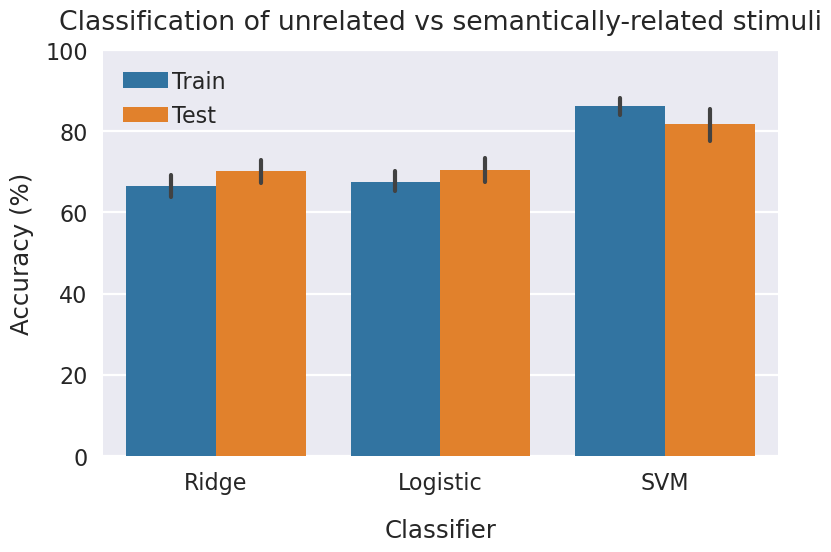

In [15]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (8.7, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0,1)

    _g = sns.barplot(y='Accuracy',
                     x='Classifier',
                     hue='Performance',
                     data=_df,
                     ax=_ax, 
                     errwidth=3,
                     ci=95)
    plt.gca().legend().set_title('')
    plt.gca().set_title('Classification of unrelated vs semantically-related stimuli', pad=15)
    
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(ylabel='Accuracy (%)', 
            yticks=locs, 
            yticklabels=list(map(int,locs*100)),
            xlabel='Classifier')

    # plt.savefig((project_path 
    #              + results_path 
    #              + fig_fname
    #              + '_5.png'),
    #             dpi=450, 
    #             bbox_inches = "tight")
    plt.show()

In [23]:
# make df of descriptive statistics
stat_df = _df.drop(columns=['step','w_train', 'Trial Length']).groupby(by=['Classifier','Performance'],
                               ).agg(['min', 'max','mean','std','sem','var']) * 100

In [25]:
stat_df

Accuracy                                             \
                              min        max       mean        std       sem   
Classifier Performance                                                         
Ridge      Test         56.666667  86.666667  70.208333   7.816126  1.477109   
           Train        50.833333  83.750000  66.458333   6.912426  1.306326   
Logistic   Test         56.666667  87.500000  70.446429   8.285300  1.565775   
           Train        54.166667  85.416667  67.574405   6.674430  1.261349   
SVM        Test         53.333333  97.500000  81.696429  10.821414  2.045055   
           Train        72.916667  95.000000  86.160714   6.308224  1.192142   

                                  
                             var  
Classifier Performance            
Ridge      Test         0.610918  
           Train        0.477816  
Logistic   Test         0.686462  
           Train        0.445480  
SVM        Test         1.171030  
           Train        0.397937

In [27]:
# make df of descriptive statistics
_df.drop(columns=['step','w_train', 'Trial Length']).groupby(by=['Classifier','Performance'],
                               ).agg(['mean','std']) * 100

Accuracy           
                             mean        std
Classifier Performance                      
Ridge      Test         70.208333   7.816126
           Train        66.458333   6.912426
Logistic   Test         70.446429   8.285300
           Train        67.574405   6.674430
SVM        Test         81.696429  10.821414
           Train        86.160714   6.308224

In [ ]:
All three classifiers, ridge, logistic regression, and SVM both performed significantly above chance (70.2%, SD=7.8, 70.4%, SD=8.2, and 81.7%, SD=10.8 respectively). Moreover, the SVM classifierdecoded semantically-related, high conflict conditions significantly better than both ridge and logistic regression classifiers (see Figure 3.1). 

In [24]:
print(stat_df.transpose().to_latex(float_format="%.2f"))

\begin{tabular}{llrrrrrr}
\toprule
         & Classifier & \multicolumn{2}{l}{Ridge} & \multicolumn{2}{l}{Logistic} & \multicolumn{2}{l}{SVM} \\
         & Performance &  Test & Train &     Test & Train &  Test & Train \\
\midrule
Accuracy & min & 56.67 & 50.83 &    56.67 & 54.17 & 53.33 & 72.92 \\
         & max & 86.67 & 83.75 &    87.50 & 85.42 & 97.50 & 95.00 \\
         & mean & 70.21 & 66.46 &    70.45 & 67.57 & 81.70 & 86.16 \\
         & std &  7.82 &  6.91 &     8.29 &  6.67 & 10.82 &  6.31 \\
         & sem &  1.48 &  1.31 &     1.57 &  1.26 &  2.05 &  1.19 \\
         & var &  0.61 &  0.48 &     0.69 &  0.45 &  1.17 &  0.40 \\
\bottomrule
\end{tabular}



In [29]:
from scipy.stats import ttest_rel

In [37]:
# T-test by classifier pairs
ind_cl = {'svm':(main_df['Classifier'] == 'SVM'),
          'lr': (main_df['Classifier'] == 'Logistic'),
          'ridge': (main_df['Classifier'] == 'Ridge'),
         }
t_ridge_svm = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['svm'],'Test Accuracy'].values)
t_ridge_lr = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['lr'],'Test Accuracy'].values)
t_svm_lr = ttest_rel(main_df.loc[ind_cl['svm'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['lr'],'Test Accuracy'].values)
rnd_fn = lambda x: np.round(x, decimals=2)
print('Ridge v. SVM:',
      [rnd_fn(t_ridge_svm[0]),np.round(t_ridge_svm[1],decimals=4)],
      '\nRidge v. Logistic Regression:',
      [rnd_fn(t_ridge_lr[0]),np.round(t_ridge_lr[1],decimals=10)],
      '\nSVM v. Logistic Regression:',
      [rnd_fn(t_svm_lr[0]),np.round(t_svm_lr[1],decimals=8)])

Ridge v. SVM: [-5.65, 0.0] 
Ridge v. Logistic Regression: [-0.14, 0.8890856326] 
SVM v. Logistic Regression: [4.36, 0.00016855]


#### UR

In [1]:
project_path = '/project_data/volume0/tpirnia/data/EEGWS/'
results_path = 'data/across_subjects/results/ch2_attempt6/ur/'
fname_root = 'ch2-_ur_c_avg.3reps_w1000_s500-rep3-2'

data_fnames = ['results_'+fname_root+'_ridge.csv',
               'results_'+fname_root+'_log.csv','results_'+fname_root+'_svm.csv']

fig_fname = 'fig_' + fname_root # add ending

exclude_subjects = ['EP24']

#### 2. Import packages

In [2]:
import os, sys
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl


import seaborn as sns

sys.path.append(project_path + '/maybe_repo')
# from utils.utils import save_output

#### 3. Load data sets  </big>
 - load each set
 - concatenate different sets (i.e. results by classifier)
 - reset index

In [3]:
main_df = []
for _fname in data_fnames:
    _df = pd.read_csv(''.join([project_path,
                               results_path,
                               _fname,
                              ])) #,usecols=list(np.arange(8))
    main_df.append(pd.DataFrame(_df))

main_df = pd.concat(main_df,
                ignore_index=True)
main_df.reset_index(inplace=True, 
                    drop=True)

In [4]:
main_df.head(3)

,subject,classifier,window,step,w_train,train_accuracy,t_0,t_500
0,EP03,ridge,1000,500,1,0.770833,0.658333,0.775
1,EP05,ridge,1000,500,1,0.841667,0.733333,0.925
2,EP06,ridge,1000,500,1,0.745833,0.700000,0.800


#### 4. Reformat data frame
 - Remove extra data:
     - only keep columns [0:train_accuracy] + [test_accuracy]
     - remove duplicates
 - Variable formatting:
     - subject -> ordered type
     - Classifier -> categorical

In [5]:
train_ind, test_ind = main_df.columns.get_indexer(['train_accuracy','t_500'])
keep_cols_ind = list(np.arange(train_ind+1)) + [test_ind]
del_cols_ind = np.delete(np.arange(len(main_df.columns)), keep_cols_ind)

print('Columns to keep:',main_df.columns.values[keep_cols_ind],
     '\nColumns to remove:',main_df.columns.values[del_cols_ind])

Columns to keep: ['subject' 'classifier' 'window' 'step' 'w_train' 'train_accuracy' 't_500'] 
Columns to remove: ['t_0']


In [6]:
main_df.drop(main_df.columns[del_cols_ind],axis=1, inplace=True)

main_df = main_df.drop_duplicates()

# if I want to only look at w_train=1
# main_df.loc[main_df['w_train']==1].head(3)#.copy

col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             't_500': 'Test Accuracy',
            }
main_df.rename(columns=col_renames,
               inplace=True)

main_df.head(3)

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,ridge,1000,500,1,0.770833,0.775
1,EP05,ridge,1000,500,1,0.841667,0.925
2,EP06,ridge,1000,500,1,0.745833,0.800


In [7]:
# change subjects to ordered type
subjects = main_df['Subject'].unique()
_cattype = pd.api.types.CategoricalDtype(categories=subjects, 
                                         ordered=True)
main_df['Subject']=main_df['Subject'].astype(_cattype)


clfs = {'ridge':'Ridge','log':'Logistic','svm':'SVM'}
for _c in clfs:
    _inds = (main_df['Classifier'] == _c)
    main_df.loc[_inds,'Classifier'] = clfs[_c]

_cattype = pd.api.types.CategoricalDtype(categories=list(clfs.values()),
                                         ordered=True)
main_df['Classifier'] = main_df['Classifier'].astype(_cattype)

#### 5. Drop t_0 (for window=1000, step=500)* 

In [8]:
if 't_0' in main_df.columns:
    main_df = main_df.drop('t_0', axis=1)

#### 6. Melt accuracy of train and test into separate rows titled 'performance'*

In [9]:
# Dataframe for train/test classification 
_df = main_df.melt(id_vars=['Subject',
                            'Classifier',
                            'Trial Length',
                            'step',
                            'w_train'],
                   var_name='Performance',
                   value_name='Accuracy')

_inds_tr, _inds_te = (_df['Performance'] == 'Train Accuracy'),(_df['Performance'] == 'Test Accuracy')
_df.loc[_inds_tr,'Performance'] = 'Train'
_df.loc[_inds_te,'Performance'] = 'Test'


In [10]:
plt.rcParams.update(plt.rcParamsDefault)
# %matplotlib inline
# plt.style.use('seaborn-darkgrid')
# plt.style.use('seaborn-poster')

In [11]:
#plot parameters:
params = {'lines.markersize':6,
          'axes.labelsize': 20,
          'axes.titlesize':20,
          'axes.labelpad':8,
          'xtick.labelsize' :16,
          'ytick.labelsize' :16,
          'xtick.major.pad':7, 
          'ytick.major.pad':6, 
          'legend.labelspacing':.5,
          'legend.handletextpad':.175,
          'legend.title_fontsize':20,
          'legend.fontsize':20,
          'figure.figsize':(8,10),
          'figure.subplot.hspace': .95,
          'figure.subplot.wspace': .95,
          'image.origin': 'lower',
          'figure.autolayout': False,
          'scatter.marker':'o',
          'savefig.dpi': 450,
          'savefig.bbox': 'tight',
          'savefig.transparent': True,
         }

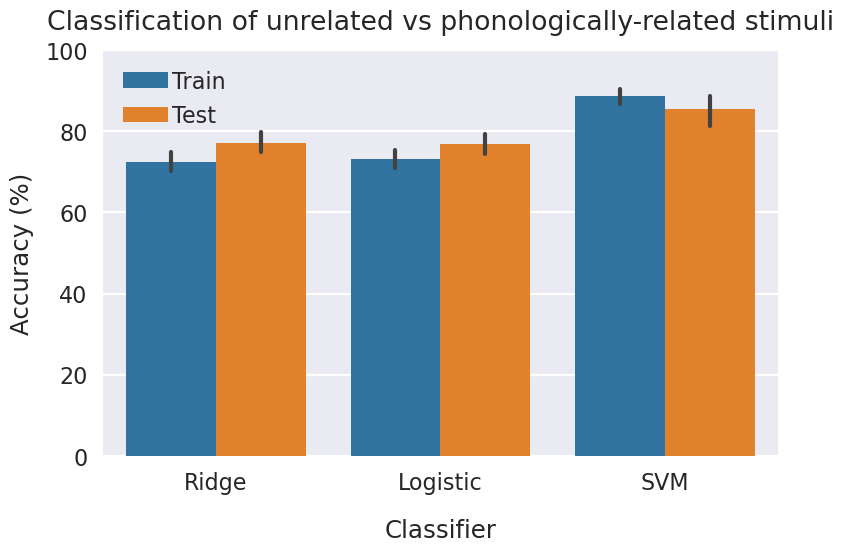

In [12]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (8.7, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0,1)

    _g = sns.barplot(y='Accuracy',
                     x='Classifier',
                     hue='Performance',
                     data=_df,
                     ax=_ax, 
                     errwidth=3,
                     ci=95)
    plt.gca().legend().set_title('')
    plt.gca().set_title('Classification of unrelated vs phonologically-related stimuli', pad=15)
    
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(ylabel='Accuracy (%)', 
            yticks=locs, 
            yticklabels=list(map(int,locs*100)),
            xlabel='Classifier')

    # plt.savefig((project_path 
    #              + results_path 
    #              + fig_fname
    #              + '_1.png'),
    #             dpi=450, 
    #             bbox_inches = "tight")
    plt.show()

In [13]:
from scipy.stats import ttest_rel

In [14]:
# make df of descriptive statistics
stat_df = _df.drop(columns=['step','w_train', 'Trial Length']).groupby(by=['Classifier','Performance'],
                               ).agg(['min', 'max','mean','std','sem','var']) * 100

In [15]:
stat_df

Accuracy                                             \
                              min        max       mean        std       sem   
Classifier Performance                                                         
Ridge      Test         60.000000  92.500000  77.172619   6.884330  1.301016   
           Train        59.583333  85.833333  72.514881   6.426502  1.214495   
Logistic   Test         60.833333  90.833333  76.815476   6.916810  1.307154   
           Train        61.666667  85.833333  73.184524   6.284590  1.187676   
SVM        Test         53.333333  98.333333  85.386905  10.431735  1.971413   
           Train        77.916667  97.500000  88.630952   5.148086  0.972897   

                                  
                             var  
Classifier Performance            
Ridge      Test         0.473940  
           Train        0.412999  
Logistic   Test         0.478423  
           Train        0.394961  
SVM        Test         1.088211  
           Train        0.265028

In [16]:
# make df of descriptive statistics
_df.drop(columns=['step','w_train', 'Trial Length']).groupby(by=['Classifier','Performance'],
                               ).agg(['mean','std']) * 100

Accuracy           
                             mean        std
Classifier Performance                      
Ridge      Test         77.172619   6.884330
           Train        72.514881   6.426502
Logistic   Test         76.815476   6.916810
           Train        73.184524   6.284590
SVM        Test         85.386905  10.431735
           Train        88.630952   5.148086

In [24]:
print(stat_df.transpose().to_latex(float_format="%.2f"))

\begin{tabular}{llrrrrrr}
\toprule
         & Classifier & \multicolumn{2}{l}{Ridge} & \multicolumn{2}{l}{Logistic} & \multicolumn{2}{l}{SVM} \\
         & Performance &  Test & Train &     Test & Train &  Test & Train \\
\midrule
Accuracy & min & 56.67 & 50.83 &    56.67 & 54.17 & 53.33 & 72.92 \\
         & max & 86.67 & 83.75 &    87.50 & 85.42 & 97.50 & 95.00 \\
         & mean & 70.21 & 66.46 &    70.45 & 67.57 & 81.70 & 86.16 \\
         & std &  7.82 &  6.91 &     8.29 &  6.67 & 10.82 &  6.31 \\
         & sem &  1.48 &  1.31 &     1.57 &  1.26 &  2.05 &  1.19 \\
         & var &  0.61 &  0.48 &     0.69 &  0.45 &  1.17 &  0.40 \\
\bottomrule
\end{tabular}



In [37]:
# T-test by classifier pairs
ind_cl = {'svm':(main_df['Classifier'] == 'SVM'),
          'lr': (main_df['Classifier'] == 'Logistic'),
          'ridge': (main_df['Classifier'] == 'Ridge'),
         }
t_ridge_svm = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['svm'],'Test Accuracy'].values)
t_ridge_lr = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['lr'],'Test Accuracy'].values)
t_svm_lr = ttest_rel(main_df.loc[ind_cl['svm'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['lr'],'Test Accuracy'].values)
rnd_fn = lambda x: np.round(x, decimals=2)
print('Ridge v. SVM:',
      [rnd_fn(t_ridge_svm[0]),np.round(t_ridge_svm[1],decimals=4)],
      '\nRidge v. Logistic Regression:',
      [rnd_fn(t_ridge_lr[0]),np.round(t_ridge_lr[1],decimals=10)],
      '\nSVM v. Logistic Regression:',
      [rnd_fn(t_svm_lr[0]),np.round(t_svm_lr[1],decimals=8)])

Ridge v. SVM: [-5.65, 0.0] 
Ridge v. Logistic Regression: [-0.14, 0.8890856326] 
SVM v. Logistic Regression: [4.36, 0.00016855]


In [ ]:
Ridge	Test	77.2%, SD=6.9

Logistic	Test	76.8%, SD=6.9

SVM	Test	85.4%, SD=10.4


All three classifiers, ridge, logistic regression, and SVM both performed significantly above chance (77.2%, SD=6.9, 76.8%, SD=6.9, and 85.4%, SD=10.4 respectively). Moreover, the SVM classifier decoded phonologically-related, high conflict conditions significantly better than both ridge and logistic regression classifiers (see Figure 4.1b). 